### Descargar y extraer los datasets CAPTURe de Hugging Face

El dataset está disponible en Hugging Face. Utilizaremos `huggingface_hub` para descargarlo y `zipfile` para extraer los archivos.

In [ ]:
import os
from huggingface_hub import hf_hub_download
import zipfile
import pandas as pd

# Descargar los archivos zip de los datasets de Hugging Face
print("Descargando real_dataset.zip...")
real_zip = hf_hub_download(repo_id="atinp/CAPTURe", filename="real_dataset.zip", repo_type="dataset")
print("Descargando synthetic_dataset.zip...")
syn_zip  = hf_hub_download(repo_id="atinp/CAPTURe", filename="synthetic_dataset.zip", repo_type="dataset")

# Descargar los archivos de metadatos de Hugging Face
print("Descargando real_metadata.json...")
real_meta = hf_hub_download(repo_id="atinp/CAPTURe", filename="real_metadata.json", repo_type="dataset")
print("Descargando synthetic_metadata.json...")
syn_meta  = hf_hub_download(repo_id="atinp/CAPTURe", filename="synthetic_metadata.json", repo_type="dataset")

# Extraer real_dataset.zip
print(f"Extrayendo {real_zip}...")
with zipfile.ZipFile(real_zip, 'r') as zip_ref:
    zip_ref.extractall()
# Renombrar la carpeta extraída (originalmente llamada 'dataset') a 'real_dataset' si existe y 'real_dataset' no existe
if os.path.exists("dataset") and not os.path.exists("real_dataset"):
    os.rename("dataset", "real_dataset")
elif os.path.exists("dataset") and os.path.exists("real_dataset"):
    print("La carpeta 'real_dataset' ya existe. Omitiendo el renombrado.")

# Extraer synthetic_dataset.zip
print(f"Extrayendo {syn_zip}...")
with zipfile.ZipFile(syn_zip, 'r') as zip_ref:
    zip_ref.extractall()
# Renombrar la carpeta extraída (originalmente llamada 'dataset') a 'synthetic_dataset' si existe y 'synthetic_dataset' no existe
if os.path.exists("dataset") and not os.path.exists("synthetic_dataset"):
    os.rename("dataset", "synthetic_dataset")
elif os.path.exists("dataset") and os.path.exists("synthetic_dataset"):
    print("La carpeta 'synthetic_dataset' ya existe. Omitiendo el renombrado.")

print("Datasets y metadatos extraídos/descargados exitosamente.")

Descargando real_dataset.zip...


real_dataset.zip:   0%|          | 0.00/46.5M [00:00<?, ?B/s]

Descargando synthetic_dataset.zip...


synthetic_dataset.zip:   0%|          | 0.00/784k [00:00<?, ?B/s]

Descargando real_metadata.json...


real_metadata.json:   0%|          | 0.00/253k [00:00<?, ?B/s]

Descargando synthetic_metadata.json...


synthetic_metadata.json:   0%|          | 0.00/1.21M [00:00<?, ?B/s]

Extrayendo /root/.cache/huggingface/hub/datasets--atinp--CAPTURe/snapshots/f2461c01456e0d051a33d888bd579cbc36ff6f60/real_dataset.zip...
Extrayendo /root/.cache/huggingface/hub/datasets--atinp--CAPTURe/snapshots/f2461c01456e0d051a33d888bd579cbc36ff6f60/synthetic_dataset.zip...
Datasets y metadatos extraídos/descargados exitosamente.


### Cargar y revisar los metadatos del dataset

Ahora, cargaremos los archivos `real_metadata.json` y `synthetic_metadata.json` en DataFrames de pandas para una revisión inicial.

In [ ]:
# Cargar real_metadata.json
try:
    # Usar la ruta devuelta por hf_hub_download
    real_metadata_df = pd.read_json(real_meta)
    print("Primeras 5 filas de real_metadata.json:")
    display(real_metadata_df.head())
except FileNotFoundError:
    print("Error: 'real_metadata.json' no encontrado. Asegúrate de que el archivo fue descargado correctamente.")

# Cargar synthetic_metadata.json
try:
    # Usar la ruta devuelta por hf_hub_download
    synthetic_metadata_df = pd.read_json(syn_meta)
    print("\nPrimeras 5 filas de synthetic_metadata.json:")
    display(synthetic_metadata_df.head())
except FileNotFoundError:
    print("Error: 'synthetic_metadata.json' no encontrado. Asegúrate de que el archivo fue descargado correctamente.")

Primeras 5 filas de real_metadata.json:


,image_file,log_prob,density_map_sum,ground_truth,object,bbox
0,1455.jpg,-0.000095,63.000008,63,keyboard keys,"{'x': 11, 'y': 33, 'width': 106, 'height': 42}"
1,1461.jpg,-0.000018,99.000008,99,keyboard keys,"{'x': 145, 'y': 172, 'width': 181, 'height': 46}"
2,1463.jpg,-0.000009,60.000004,60,keyboard keys,"{'x': 162, 'y': 108, 'width': 268, 'height': 120}"
3,1894.jpg,-0.000097,32.000008,32,bottle caps,"{'x': 134, 'y': 115, 'width': 183, 'height': 170}"
4,1895.jpg,-0.000010,29.999994,30,bottle caps,"{'x': 46, 'y': 129, 'width': 356, 'height': 238}"



Primeras 5 filas de synthetic_metadata.json:


,image_file,ground_truth,shape,offset,color,num_occluded,dot_shape,positions
0,circle_5_dots_0_blue_dots.png,5,circle,"[0, 0]",blue,1,circle,"[[150.0, 100.0], [115.45, 147.55], [59.55, 129..."
1,circle_5_dots_0_blue_boxes.png,5,circle,"[0, 0]",blue,1,square,"[[150.0, 100.0], [115.45, 147.55], [59.55, 129..."
2,circle_5_dots_0_green_dots.png,5,circle,"[0, 0]",green,1,circle,"[[150.0, 100.0], [115.45, 147.55], [59.55, 129..."
3,circle_5_dots_0_green_boxes.png,5,circle,"[0, 0]",green,1,square,"[[150.0, 100.0], [115.45, 147.55], [59.55, 129..."
4,circle_5_dots_0_red_dots.png,5,circle,"[0, 0]",red,1,circle,"[[150.0, 100.0], [115.45, 147.55], [59.55, 129..."


### Verificacion del dataset completo (real_validation_metadata desde GitHub)

El release de HuggingFace de `atinp/CAPTURe` **no incluye** `real_validation_metadata.json` (las 100 filas de validacion, con `bbox` de objetos via `annotation_bboxes` -- necesarias para la fase de explicabilidad). Ese archivo solo existe en el repo de GitHub del paper (`atinpothiraj/CAPTURe`). Esta celda lo descarga y corre las mismas verificaciones que se hicieron manualmente para confirmar que el dataset completo (824 test + 100 validacion = 924, como reporta el paper) esta disponible y es consistente antes de construir nada sobre el.

In [ ]:
import json
import urllib.request
import pandas as pd

GITHUB_RAW = "https://raw.githubusercontent.com/atinpothiraj/CAPTURe/main"

def descargar_json_github(nombre_archivo):
    url = f"{GITHUB_RAW}/{nombre_archivo}"
    with urllib.request.urlopen(url) as resp:
        return json.load(resp)

print("Descargando real_validation_metadata.json desde GitHub (no existe en HuggingFace)...")
validation_data = descargar_json_github("real_validation_metadata.json")
validation_df = pd.DataFrame(validation_data)

print(f"Filas en real_validation_metadata.json: {len(validation_df)}  (esperado: 100)")
print(f"Columnas: {list(validation_df.columns)}")

# 1. Disjuntas respecto al set de test (real_metadata_df, ya cargado en HF arriba)
overlap = set(validation_df["image_file"]) & set(real_metadata_df["image_file"])
print(f"\nOverlap image_file entre test (824) y validacion (100): {len(overlap)}  (esperado: 0)")

# 2. Media de ground_truth sobre la union -- debe coincidir con la Tabla 1 del paper (61.45)
media_union = pd.concat([real_metadata_df["ground_truth"], validation_df["ground_truth"]]).mean()
print(f"Media ground_truth union (824+100={len(real_metadata_df)+len(validation_df)}): "
      f"{media_union:.4f}  (paper Tabla 1: 61.45)")

# 3. annotation_bboxes: separar puntos (objetos) de exemplars FSC-147, verificar
#    len(puntos) == ground_truth en la mayoria de filas
def separar_anotaciones(ab):
    puntos = [b for b in ab if b[2] <= 3 and b[3] <= 3]
    ejemplos = [b for b in ab if b[2] > 3 or b[3] > 3]
    return puntos, ejemplos

n_ok = 0
anomalias = []
for idx, row in validation_df.iterrows():
    puntos, ejemplos = separar_anotaciones(row["annotation_bboxes"])
    if len(puntos) == row["ground_truth"]:
        n_ok += 1
    else:
        anomalias.append((idx, row["image_file"], row["ground_truth"], len(puntos)))

print(f"\nannotation_bboxes: len(puntos) == ground_truth en {n_ok}/{len(validation_df)} filas")
if anomalias:
    print("Filas anomalas (revisar antes de usar en explicabilidad):")
    for a in anomalias:
        print(f"  idx={a[0]} image_file={a[1]} ground_truth={a[2]} puntos_encontrados={a[3]}")

# 4. basic_occluded_images -- solo se listan los nombres, NO se verifica aqui que los
#    archivos existan fisicamente en el zip de HuggingFace (bloqueado desde algunos entornos).
#    Verificar el namelist del zip antes de construir nada que dependa de esto.
print(f"\nEjemplo basic_occluded_images (fila 0): {validation_df.iloc[0]['basic_occluded_images']}")
print(f"Ejemplo questions (fila 0): {validation_df.iloc[0]['questions']}")

print("\n--- Resumen ---")
checks_ok = (len(validation_df) == 100 and len(overlap) == 0 and abs(media_union - 61.45) < 0.01)
print("TODO OK, dataset de validacion completo y consistente con el paper."
      if checks_ok else
      "REVISAR -- algun chequeo no paso, ver detalle arriba antes de usar este dataset.")


### Información general y forma de los DataFrames de metadatos

Veamos la información general (`.info()`) y la forma (`.shape`) de los DataFrames `real_metadata_df` y `synthetic_metadata_df` para entender su estructura.

In [ ]:
print("\n--- Información de real_metadata_df ---")
real_metadata_df.info()
print("Shape de real_metadata_df:", real_metadata_df.shape)

print("\n--- Información de synthetic_metadata_df ---")
synthetic_metadata_df.info()
print("Shape de synthetic_metadata_df:", synthetic_metadata_df.shape)


--- Información de real_metadata_df ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 824 entries, 0 to 823
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   image_file       824 non-null    object 
 1   log_prob         824 non-null    float64
 2   density_map_sum  824 non-null    float64
 3   ground_truth     824 non-null    int64  
 4   object           824 non-null    object 
 5   bbox             824 non-null    object 
dtypes: float64(2), int64(1), object(3)
memory usage: 38.8+ KB
Shape de real_metadata_df: (824, 6)

--- Información de synthetic_metadata_df ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1150 entries, 0 to 1149
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   image_file    1150 non-null   object
 1   ground_truth  1150 non-null   int64 
 2   shape         1150 non-null   object
 3   offset        1150 no

### Estadísticas descriptivas de los DataFrames

Analicemos las estadísticas descriptivas de las columnas numéricas para ambos DataFrames (`real_metadata_df` y `synthetic_metadata_df`). Esto nos ayudará a entender la distribución, el rango y los valores centrales de los datos.

In [ ]:
print("\n--- Estadísticas descriptivas de real_metadata_df ---")
display(real_metadata_df.describe())

print("\n--- Estadísticas descriptivas de synthetic_metadata_df ---")
display(synthetic_metadata_df.describe())


--- Estadísticas descriptivas de real_metadata_df ---


,log_prob,density_map_sum,ground_truth
count,8.240000e+02,824.000000,824.000000
mean,-2.348751e-05,60.415049,60.415049
std,2.342826e-05,89.610461,89.610457
min,-9.925185e-05,7.999998,8.000000
25%,-3.205079e-05,15.000000,15.000000
50%,-1.396164e-05,28.500003,28.500000
75%,-6.034592e-06,67.250017,67.250000
max,-5.512237e-07,906.999878,907.000000



--- Estadísticas descriptivas de synthetic_metadata_df ---


,ground_truth,num_occluded
count,1150.000000,1150.000000
mean,10.018261,2.726957
std,3.238505,1.965823
min,5.000000,1.000000
25%,7.000000,1.000000
50%,10.000000,3.000000
75%,13.000000,3.000000
max,15.000000,13.000000


### Análisis de columnas categóricas

Vamos a revisar las columnas categóricas para entender qué tipo de valores contienen y su distribución en los datasets.

In [ ]:
print("\n--- Valores únicos y conteos para real_metadata_df ---")
for col in ['object']:
    if col in real_metadata_df.columns and real_metadata_df[col].dtype == 'object': # Check if it's an object type (likely categorical)
        print(f"\nColumna '{col}':")
        # Use display for real_metadata_df as it worked fine previously
        display(real_metadata_df[col].value_counts())

print("\n--- Valores únicos y conteos para synthetic_metadata_df ---")
for col in ['shape', 'color', 'dot_shape']:
    if col in synthetic_metadata_df.columns and synthetic_metadata_df[col].dtype == 'object': # Check if it's an object type (likely categorical)
        print(f"\nColumna '{col}':")
        # Use .to_string() to ensure full output is printed and avoid truncation
        print(synthetic_metadata_df[col].value_counts().to_string())


--- Valores únicos y conteos para real_metadata_df ---

Columna 'object':


,count
object,
cupcake tray,73
bread rolls,56
candles,42
beads,35
chairs,34
...,...
skateboard,1
boats,1
milk cartons,1



--- Valores únicos y conteos para synthetic_metadata_df ---

Columna 'shape':
shape
circle       507
rectangle    505
triangle     138

Columna 'color':
color
blue      235
red       232
purple    232
orange    228
green     223

Columna 'dot_shape':
dot_shape
circle    577
square    573


### Comparación de la Cantidad de Preguntas por Dataset

Aquí se muestra un gráfico de barras comparando el número total de entradas en `real_metadata_df` y `synthetic_metadata_df`, que podemos interpretar como la cantidad de preguntas en cada dataset.

/tmp/ipykernel_619/2678569273.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Dataset', y='Cantidad de Preguntas', data=question_counts, palette='viridis')


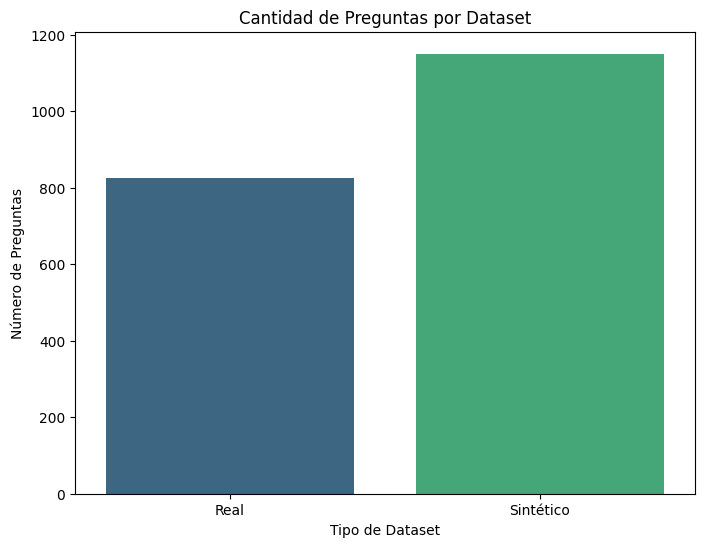

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Obtener el número de entradas en cada DataFrame
num_real_questions = len(real_metadata_df)
num_synthetic_questions = len(synthetic_metadata_df)

# Crear un DataFrame para el gráfico
question_counts = pd.DataFrame({
    'Dataset': ['Real', 'Sintético'],
    'Cantidad de Preguntas': [num_real_questions, num_synthetic_questions]
})

# Crear el gráfico de barras
plt.figure(figsize=(8, 6))
sns.barplot(x='Dataset', y='Cantidad de Preguntas', data=question_counts, palette='viridis')
plt.title('Cantidad de Preguntas por Dataset')
plt.ylabel('Número de Preguntas')
plt.xlabel('Tipo de Dataset')
plt.show()

### Formato de Cada Categoría en `real_metadata_df`

A continuación, se muestra la primera pregunta encontrada para cada categoría única en el dataset real, junto con su `ground_truth` y la imagen correspondiente. La categoría aquí es el tipo de objeto (`object`).

Ejemplos de categorías en real_metadata_df:

Categoría: 'keyboard keys'
  Ground Truth (Cantidad): 63
  Archivo de Imagen: 1455.jpg


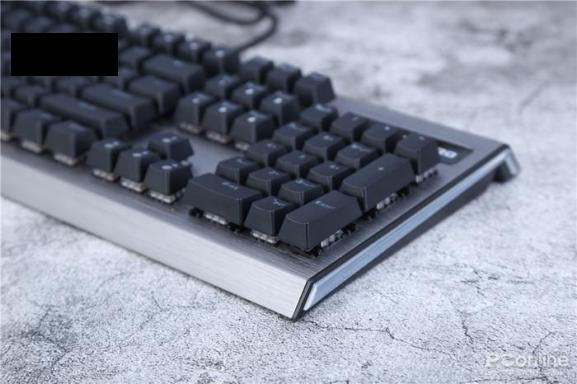


Categoría: 'bottle caps'
  Ground Truth (Cantidad): 32
  Archivo de Imagen: 1894.jpg


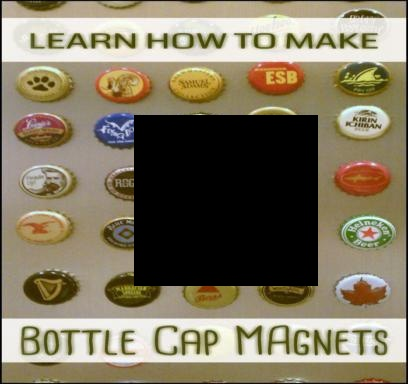


Categoría: 'sunglasses'
  Ground Truth (Cantidad): 226
  Archivo de Imagen: 2004.jpg


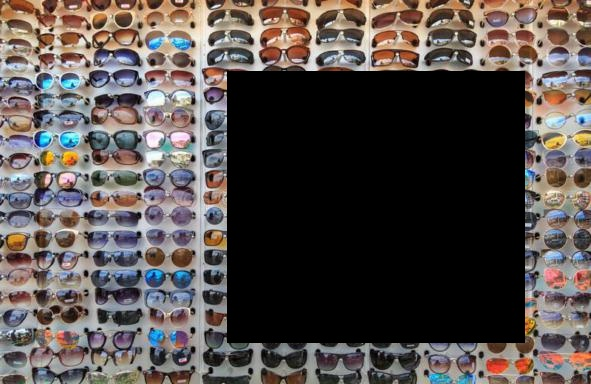


Categoría: 'balls'
  Ground Truth (Cantidad): 9
  Archivo de Imagen: 202.jpg


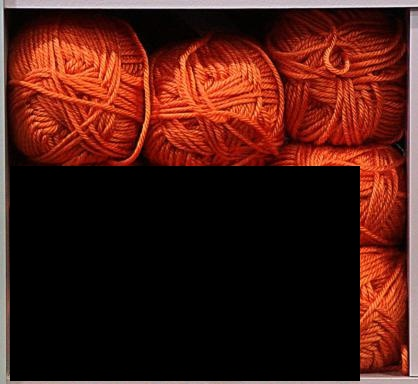


Categoría: 'apples'
  Ground Truth (Cantidad): 21
  Archivo de Imagen: 2140.jpg


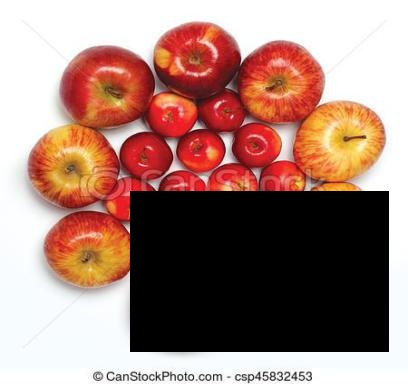


Categoría: 'stapler pins'
  Ground Truth (Cantidad): 15
  Archivo de Imagen: 2289.jpg


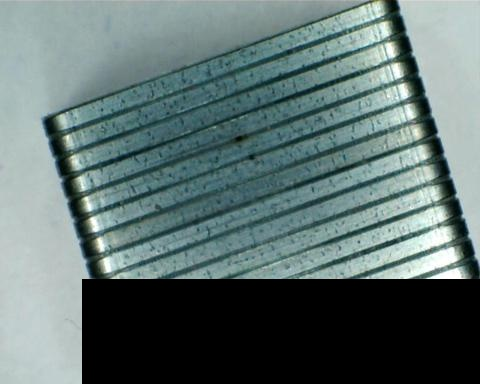


Categoría: 'bricks'
  Ground Truth (Cantidad): 80
  Archivo de Imagen: 2321.jpg


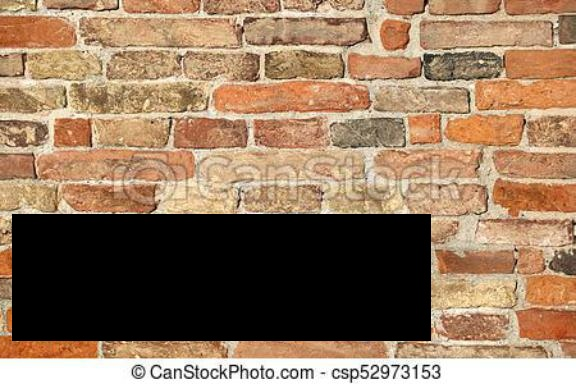


Categoría: 'cups'
  Ground Truth (Cantidad): 17
  Archivo de Imagen: 2415.jpg


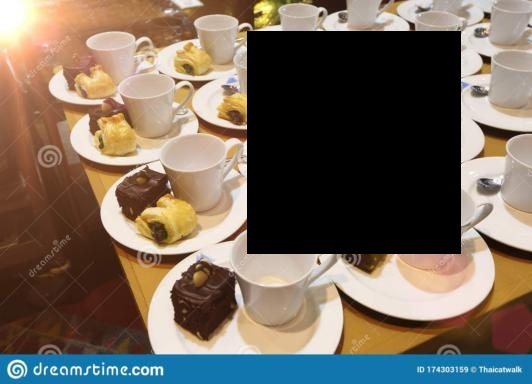


Categoría: 'grapes'
  Ground Truth (Cantidad): 12
  Archivo de Imagen: 244.jpg


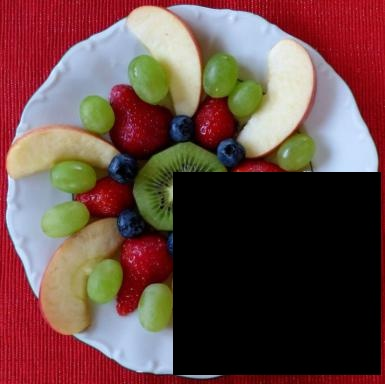


Categoría: 'windows'
  Ground Truth (Cantidad): 12
  Archivo de Imagen: 2447.jpg


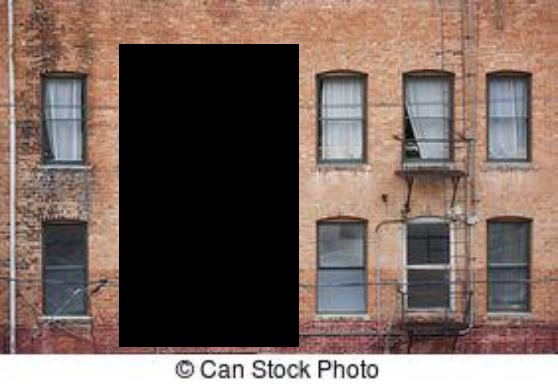


Categoría: 'lipstick'
  Ground Truth (Cantidad): 14
  Archivo de Imagen: 2483.jpg


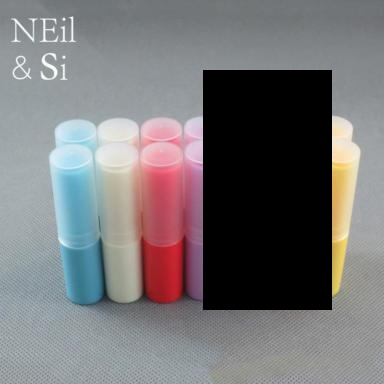


Categoría: 'spoon'
  Ground Truth (Cantidad): 13
  Archivo de Imagen: 2526.jpg


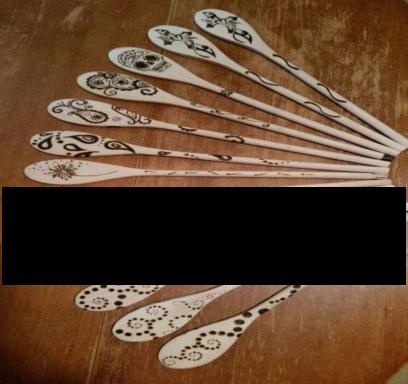


Categoría: 'bowls'
  Ground Truth (Cantidad): 47
  Archivo de Imagen: 2676.jpg


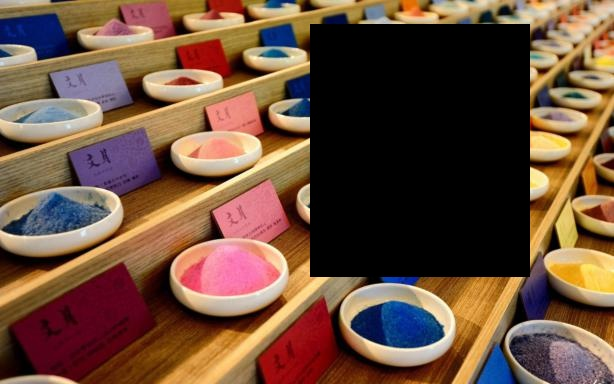


Categoría: 'go game'
  Ground Truth (Cantidad): 12
  Archivo de Imagen: 2690.jpg


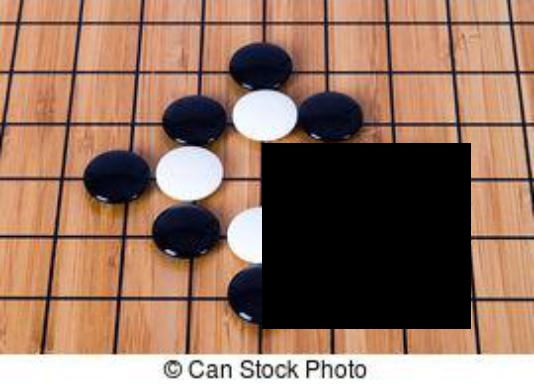


Categoría: 'oranges'
  Ground Truth (Cantidad): 38
  Archivo de Imagen: 2697.jpg


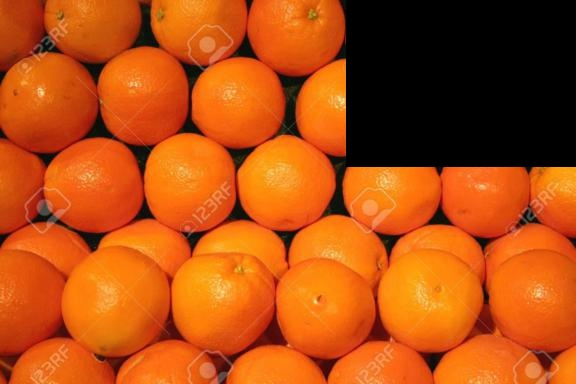


Categoría: 'candles'
  Ground Truth (Cantidad): 33
  Archivo de Imagen: 270.jpg


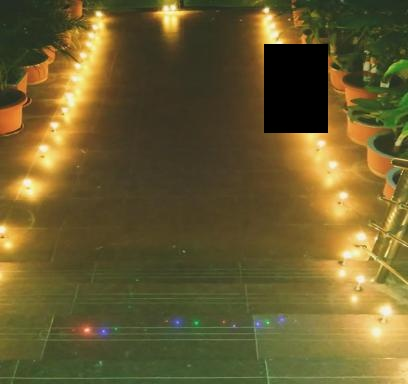


Categoría: 'oysters'
  Ground Truth (Cantidad): 9
  Archivo de Imagen: 271.jpg


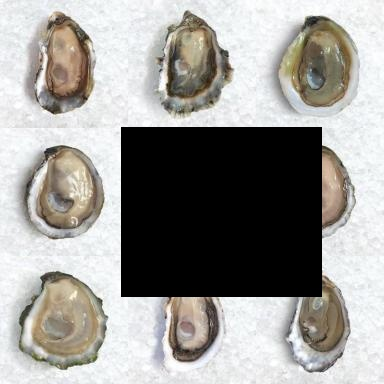


Categoría: 'cans'
  Ground Truth (Cantidad): 108
  Archivo de Imagen: 2770.jpg


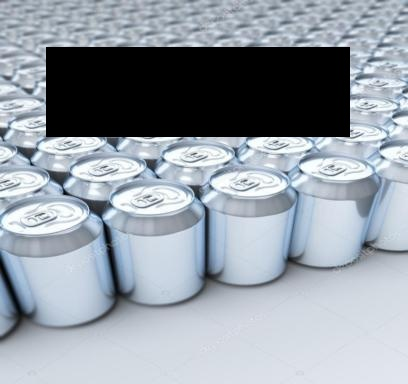


Categoría: 'chairs'
  Ground Truth (Cantidad): 263
  Archivo de Imagen: 2807.jpg


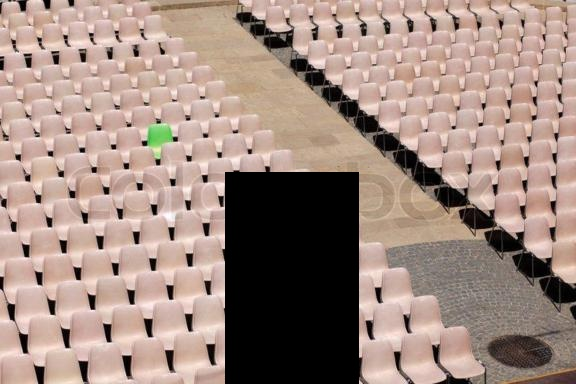


Categoría: 'mini blinds'
  Ground Truth (Cantidad): 15
  Archivo de Imagen: 2990.jpg


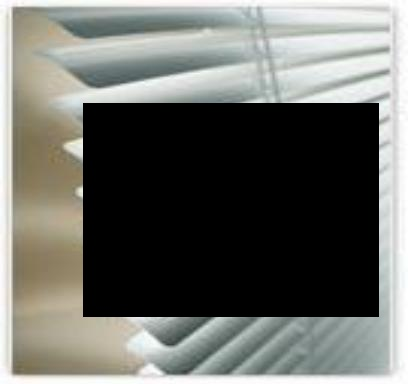


Categoría: 'bread rolls'
  Ground Truth (Cantidad): 15
  Archivo de Imagen: 3090.jpg


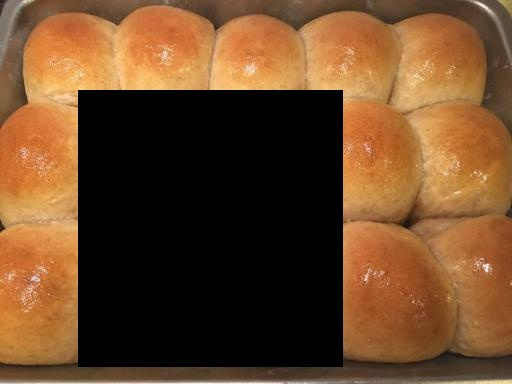


Categoría: 'coffee beans'
  Ground Truth (Cantidad): 25
  Archivo de Imagen: 3132.jpg


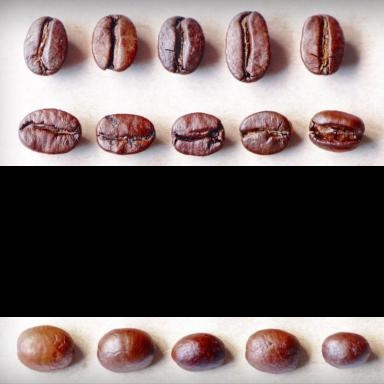


Categoría: 'buns'
  Ground Truth (Cantidad): 8
  Archivo de Imagen: 3167.jpg


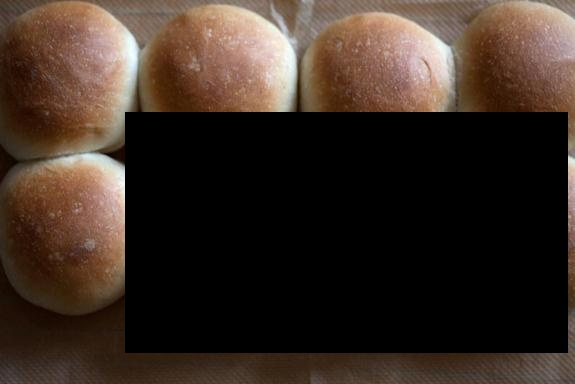


Categoría: 'bullets'
  Ground Truth (Cantidad): 35
  Archivo de Imagen: 3265.jpg


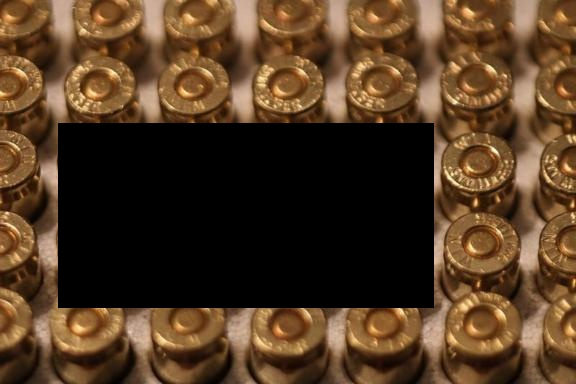


Categoría: 'finger foods'
  Ground Truth (Cantidad): 21
  Archivo de Imagen: 3271.jpg


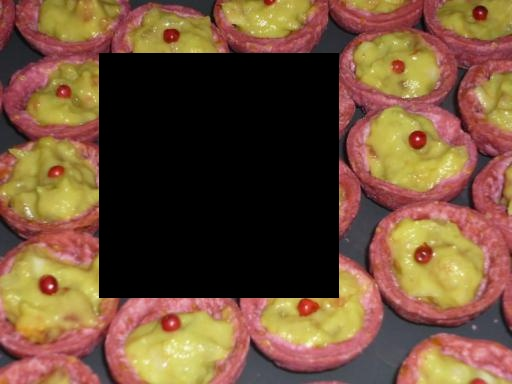


Categoría: 'macarons'
  Ground Truth (Cantidad): 17
  Archivo de Imagen: 3290.jpg


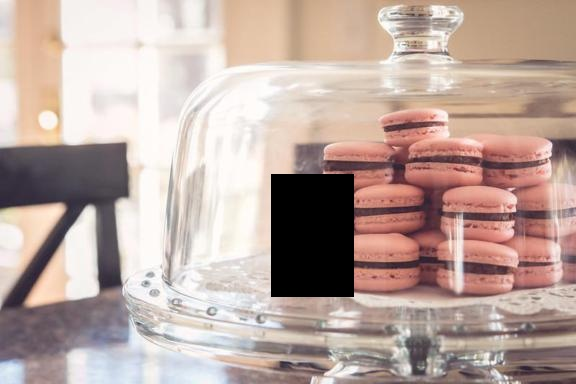


Categoría: 'cupcake tray'
  Ground Truth (Cantidad): 12
  Archivo de Imagen: 3295.jpg


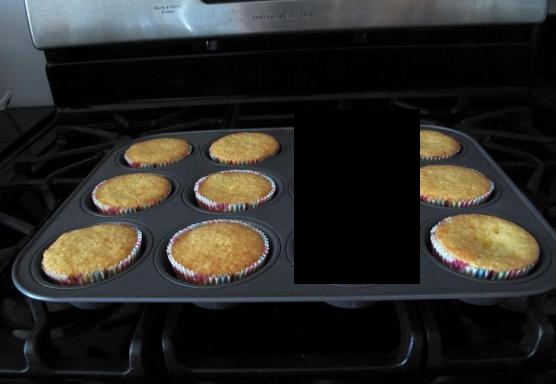


Categoría: 'green peas'
  Ground Truth (Cantidad): 136
  Archivo de Imagen: 3312.jpg


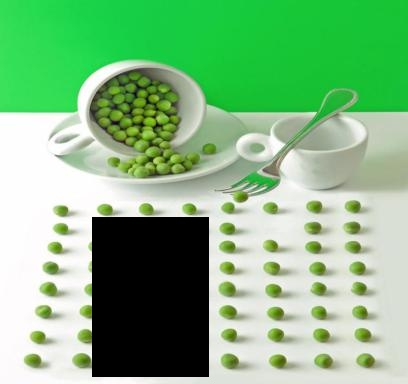


Categoría: 'sea shells'
  Ground Truth (Cantidad): 36
  Archivo de Imagen: 3341.jpg


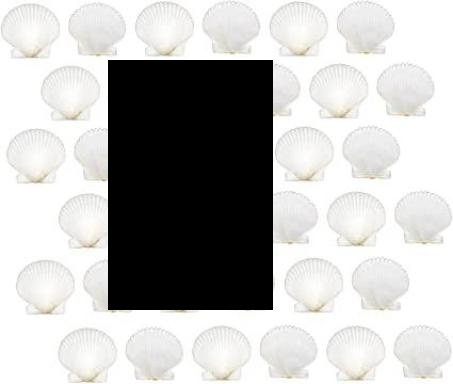


Categoría: 'nuts'
  Ground Truth (Cantidad): 42
  Archivo de Imagen: 3401.jpg


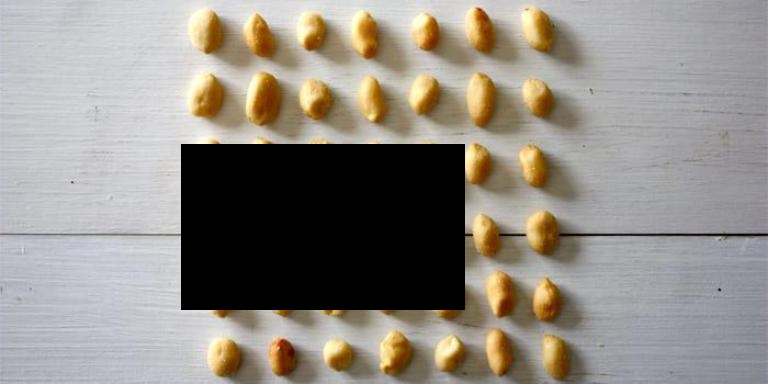


Categoría: 'polka dots'
  Ground Truth (Cantidad): 885
  Archivo de Imagen: 3425.jpg


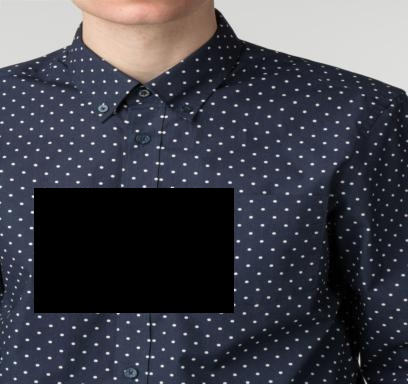


Categoría: 'instant noodles'
  Ground Truth (Cantidad): 28
  Archivo de Imagen: 3444.jpg


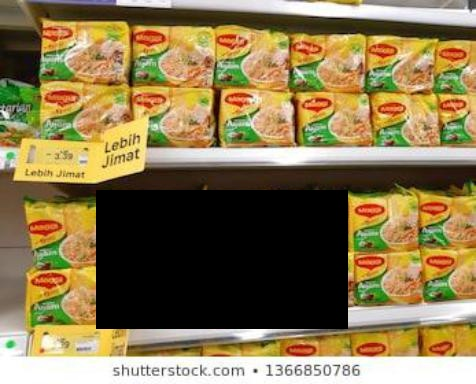


Categoría: 'beads'
  Ground Truth (Cantidad): 41
  Archivo de Imagen: 3468.jpg


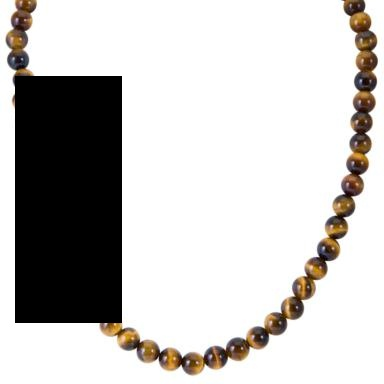


Categoría: 'chicken wings'
  Ground Truth (Cantidad): 28
  Archivo de Imagen: 3540.jpg


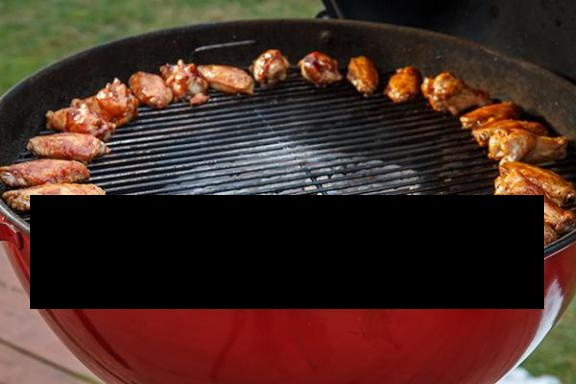


Categoría: 'gemstones'
  Ground Truth (Cantidad): 12
  Archivo de Imagen: 3617.jpg


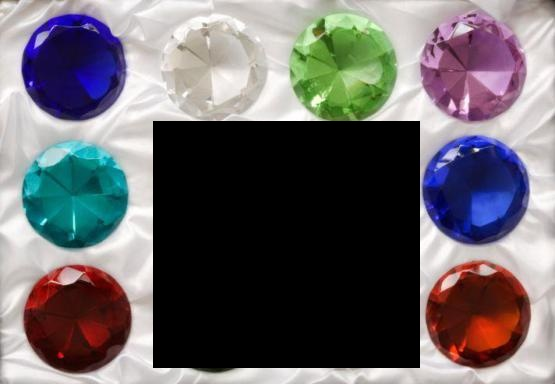


Categoría: 'kitchen towels'
  Ground Truth (Cantidad): 28
  Archivo de Imagen: 3623.jpg


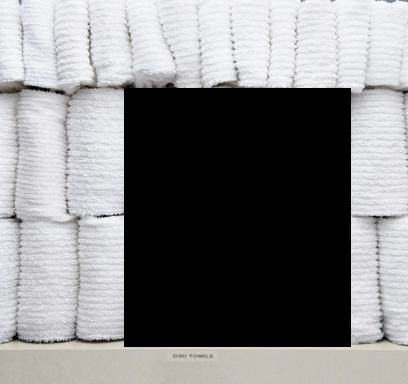


Categoría: 'toilet paper rolls'
  Ground Truth (Cantidad): 9
  Archivo de Imagen: 3661.jpg


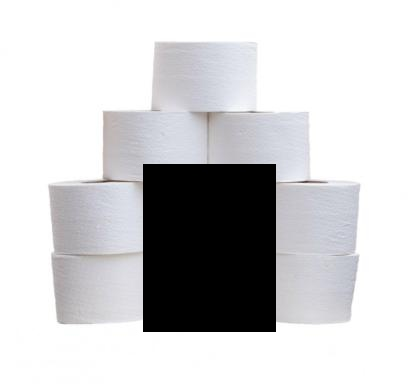


Categoría: 'chewing gum pieces'
  Ground Truth (Cantidad): 12
  Archivo de Imagen: 3708.jpg


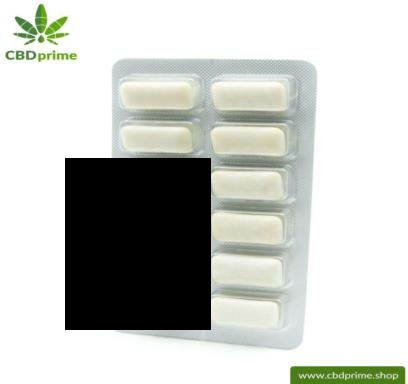


Categoría: 'pearls'
  Ground Truth (Cantidad): 131
  Archivo de Imagen: 3754.jpg


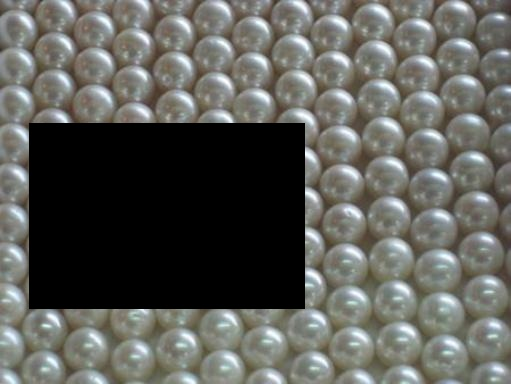


Categoría: 'donuts tray'
  Ground Truth (Cantidad): 12
  Archivo de Imagen: 3759.jpg


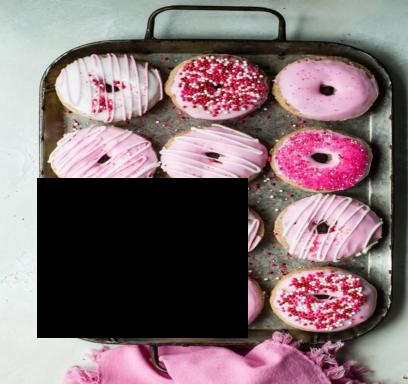


Categoría: 'crayons'
  Ground Truth (Cantidad): 12
  Archivo de Imagen: 3805.jpg


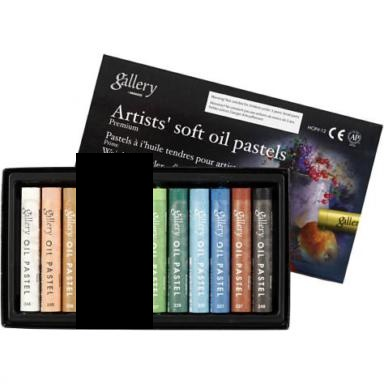


Categoría: 'cupcakes'
  Ground Truth (Cantidad): 45
  Archivo de Imagen: 3811.jpg


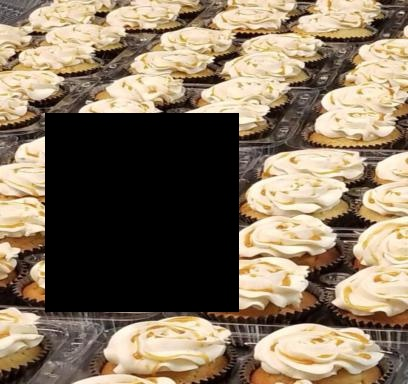


Categoría: 'stairs'
  Ground Truth (Cantidad): 15
  Archivo de Imagen: 3852.jpg


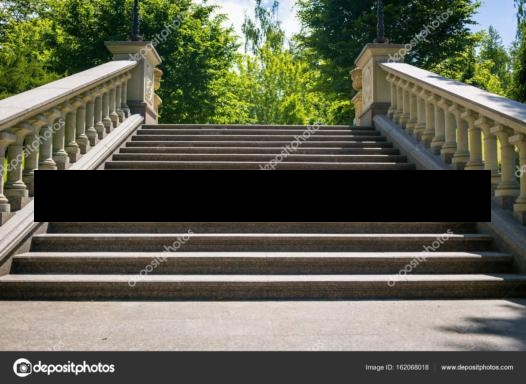


Categoría: 'screws'
  Ground Truth (Cantidad): 100
  Archivo de Imagen: 3982.jpg


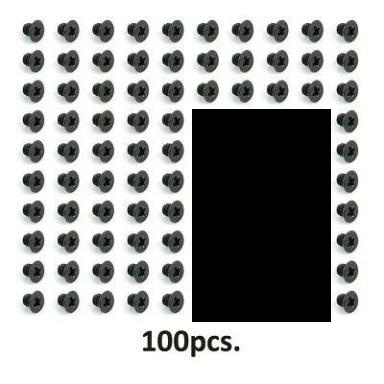


Categoría: 'goldfish snack'
  Ground Truth (Cantidad): 103
  Archivo de Imagen: 3990.jpg


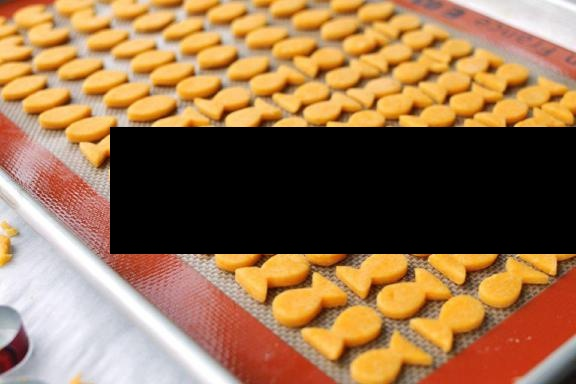


Categoría: 'marbles'
  Ground Truth (Cantidad): 25
  Archivo de Imagen: 4073.jpg


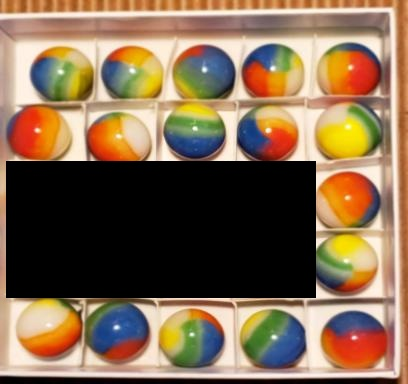


Categoría: 'mosaic tiles'
  Ground Truth (Cantidad): 144
  Archivo de Imagen: 4124.jpg


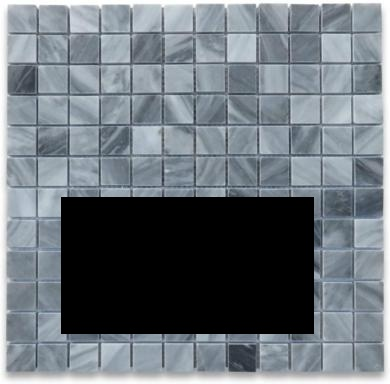


Categoría: 'sausages'
  Ground Truth (Cantidad): 10
  Archivo de Imagen: 4167.jpg


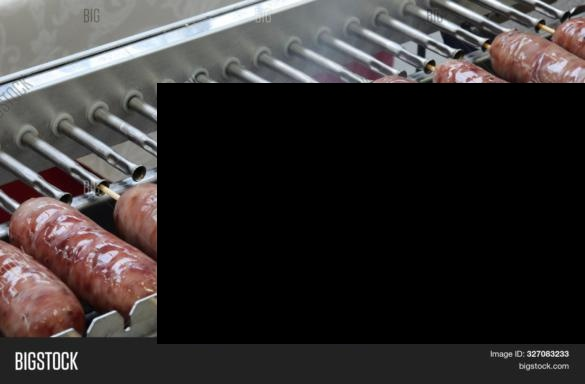


Categoría: 'biscuits'
  Ground Truth (Cantidad): 31
  Archivo de Imagen: 4191.jpg


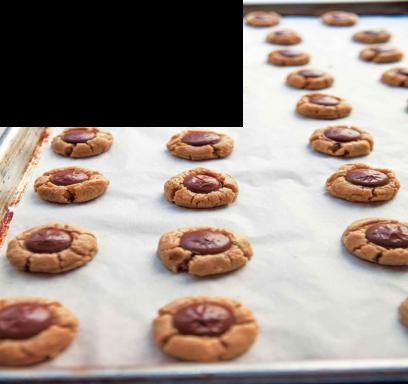


Categoría: 'clams'
  Ground Truth (Cantidad): 12
  Archivo de Imagen: 4308.jpg


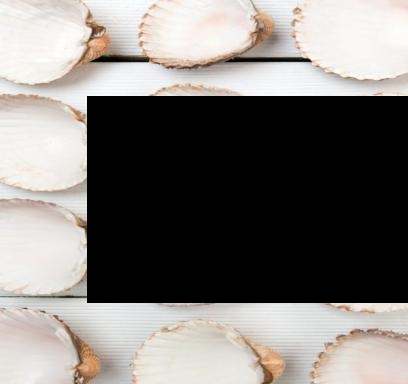


Categoría: 'nails'
  Ground Truth (Cantidad): 115
  Archivo de Imagen: 4314.jpg


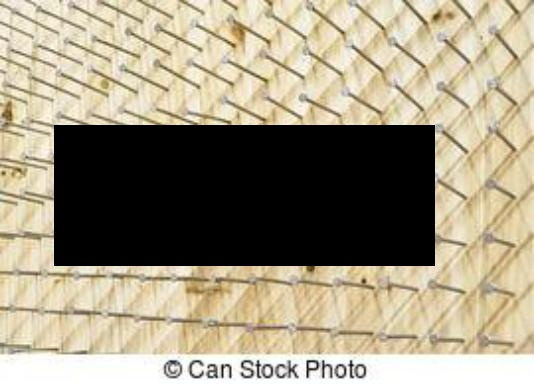


Categoría: 'peppers'
  Ground Truth (Cantidad): 32
  Archivo de Imagen: 4425.jpg


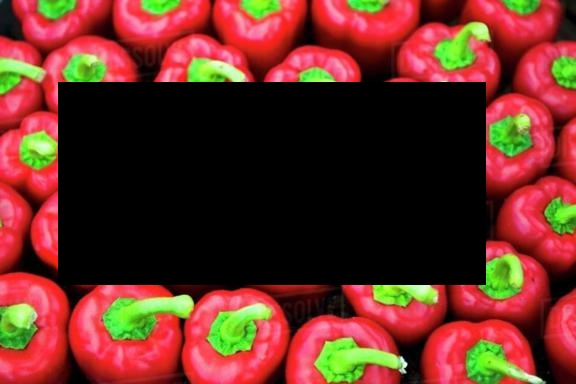


Categoría: 'tomatoes'
  Ground Truth (Cantidad): 48
  Archivo de Imagen: 4477.jpg


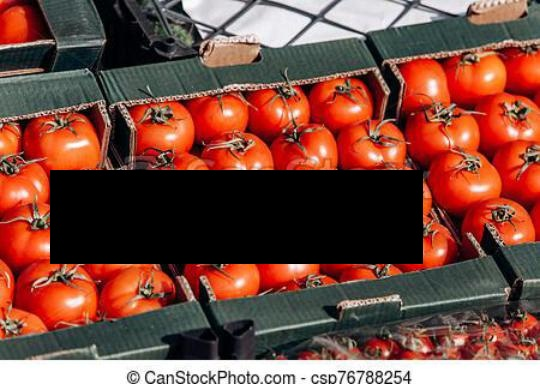


Categoría: 'kiwis'
  Ground Truth (Cantidad): 33
  Archivo de Imagen: 4587.jpg


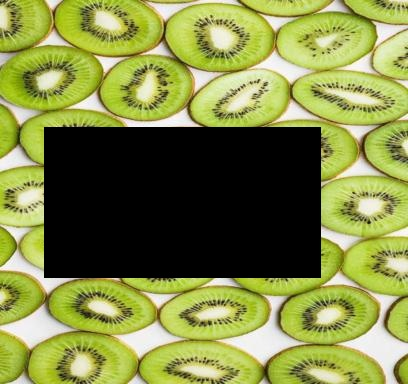


Categoría: 'geese'
  Ground Truth (Cantidad): 35
  Archivo de Imagen: 4657.jpg


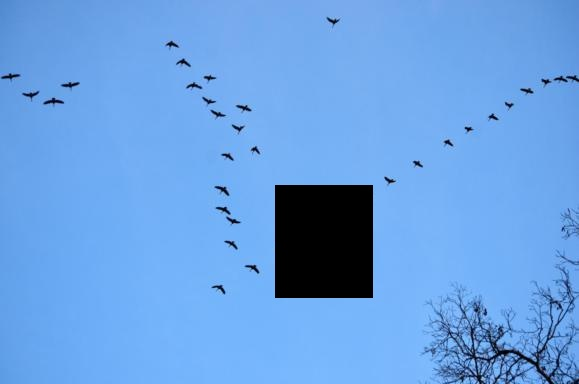


Categoría: 'ice cream'
  Ground Truth (Cantidad): 12
  Archivo de Imagen: 5124.jpg


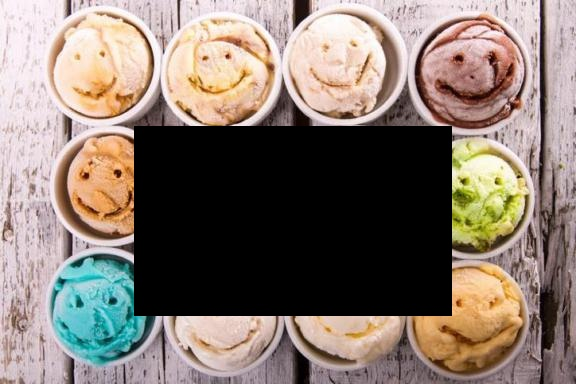


Categoría: 'jade stones'
  Ground Truth (Cantidad): 16
  Archivo de Imagen: 5138.jpg


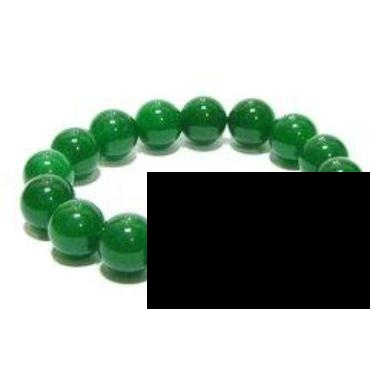


Categoría: 'cotton balls'
  Ground Truth (Cantidad): 61
  Archivo de Imagen: 5648.jpg


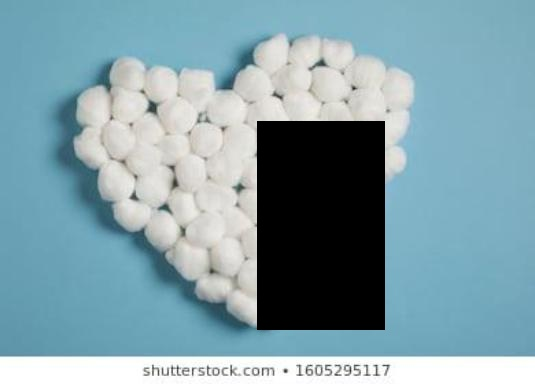


Categoría: 'strawberries'
  Ground Truth (Cantidad): 34
  Archivo de Imagen: 5814.jpg


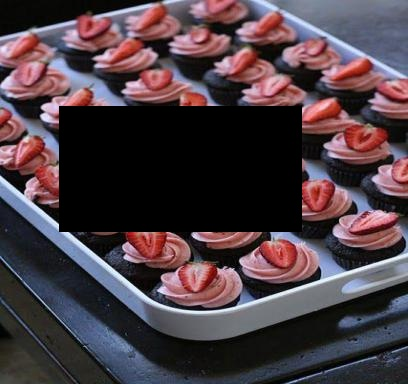


Categoría: 'eggs'
  Ground Truth (Cantidad): 12
  Archivo de Imagen: 5915.jpg


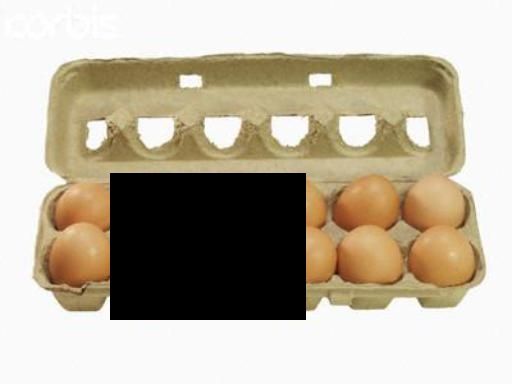


Categoría: 'cars'
  Ground Truth (Cantidad): 73
  Archivo de Imagen: 6124.jpg


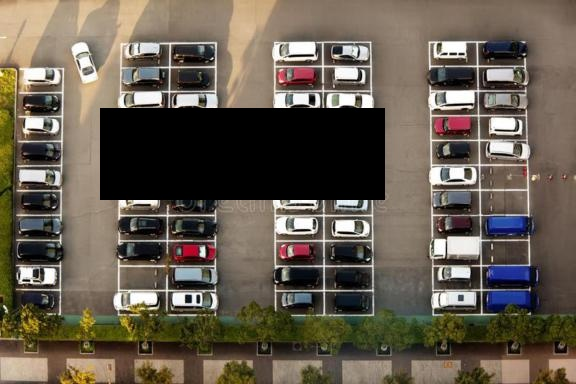


Categoría: 'coins'
  Ground Truth (Cantidad): 72
  Archivo de Imagen: 6225.jpg


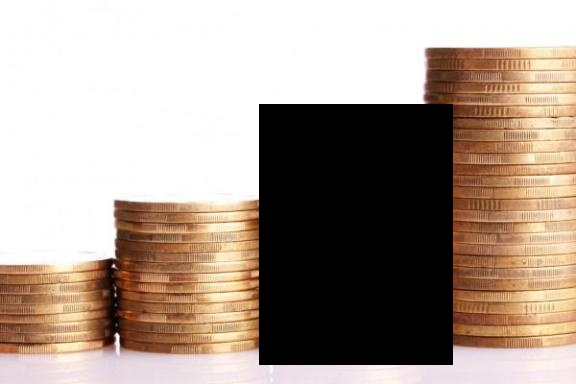


Categoría: 'pills'
  Ground Truth (Cantidad): 16
  Archivo de Imagen: 6297.jpg


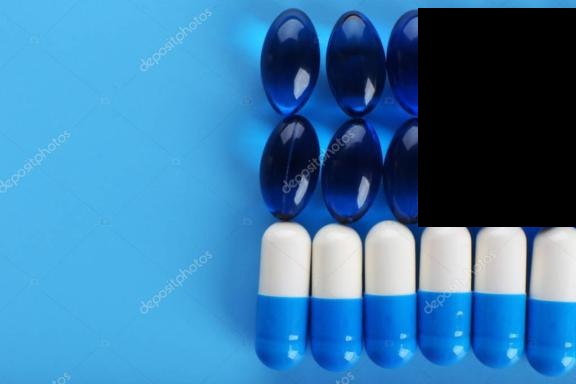


Categoría: 'roof tiles'
  Ground Truth (Cantidad): 27
  Archivo de Imagen: 6311.jpg


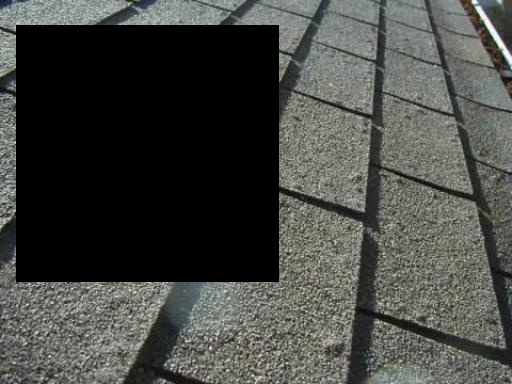


Categoría: 'shoes'
  Ground Truth (Cantidad): 52
  Archivo de Imagen: 6363.jpg


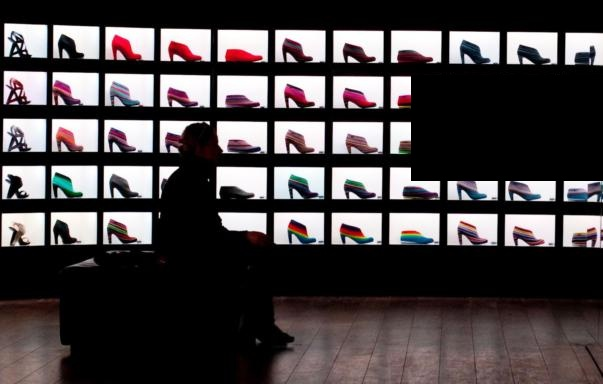


Categoría: 'pencils'
  Ground Truth (Cantidad): 12
  Archivo de Imagen: 6600.jpg


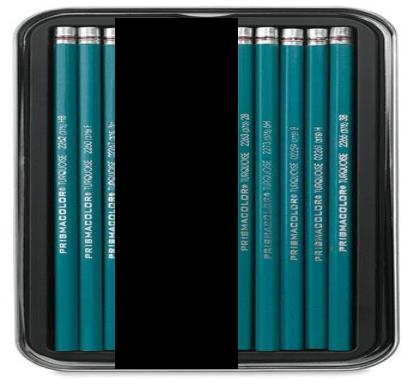


Categoría: 'markers'
  Ground Truth (Cantidad): 48
  Archivo de Imagen: 6648.jpg


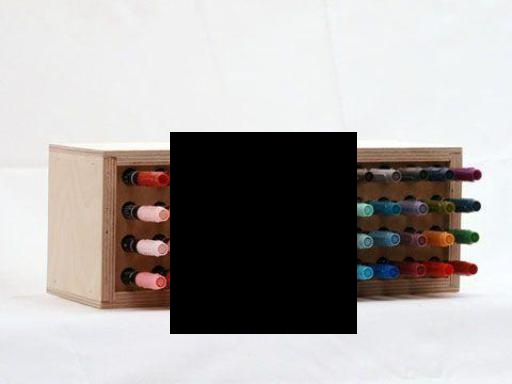


Categoría: 'shirts'
  Ground Truth (Cantidad): 36
  Archivo de Imagen: 6722.jpg


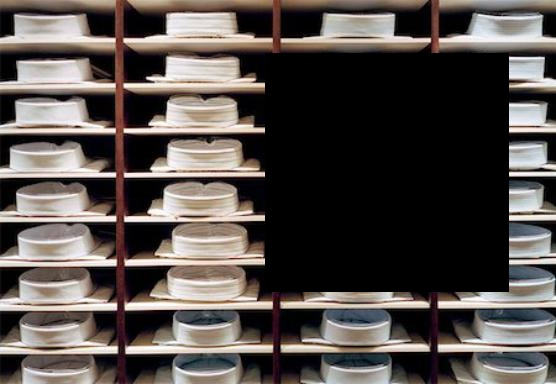


Categoría: 'flowers'
  Ground Truth (Cantidad): 20
  Archivo de Imagen: 6725.jpg


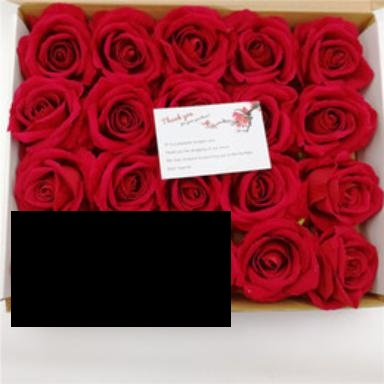


Categoría: 'comic books'
  Ground Truth (Cantidad): 24
  Archivo de Imagen: 6742.jpg


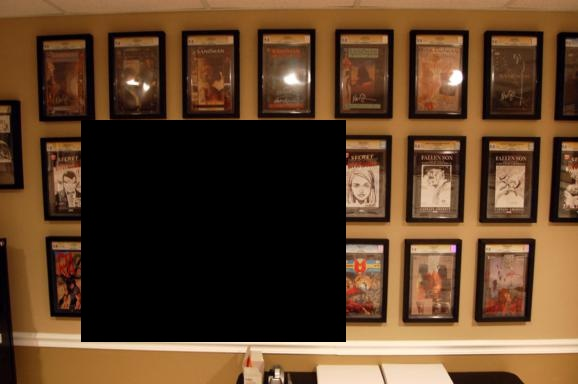


Categoría: 'carrom board pieces'
  Ground Truth (Cantidad): 19
  Archivo de Imagen: 6743.jpg


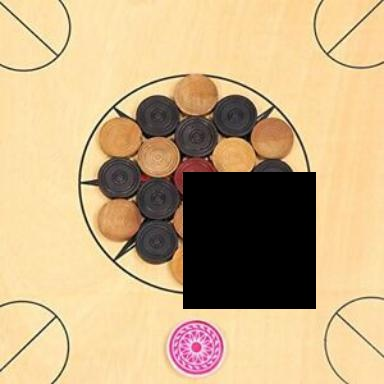


Categoría: 'nail polish'
  Ground Truth (Cantidad): 40
  Archivo de Imagen: 6810.jpg


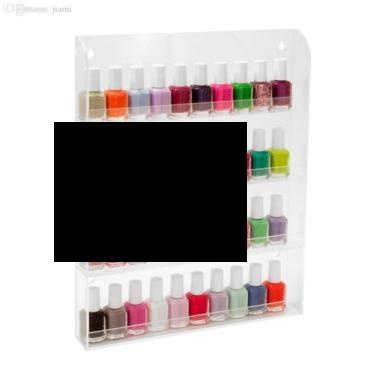


Categoría: 'boxes'
  Ground Truth (Cantidad): 42
  Archivo de Imagen: 6821.jpg


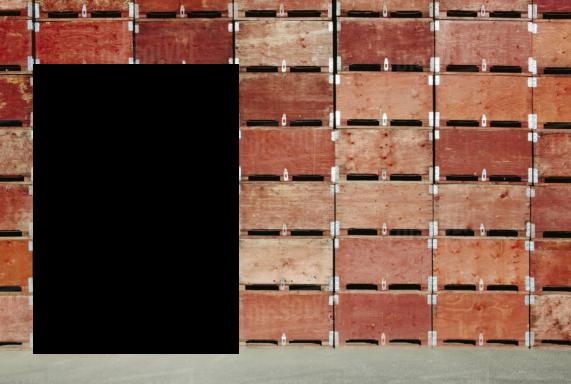


Categoría: 'caps'
  Ground Truth (Cantidad): 40
  Archivo de Imagen: 6841.jpg


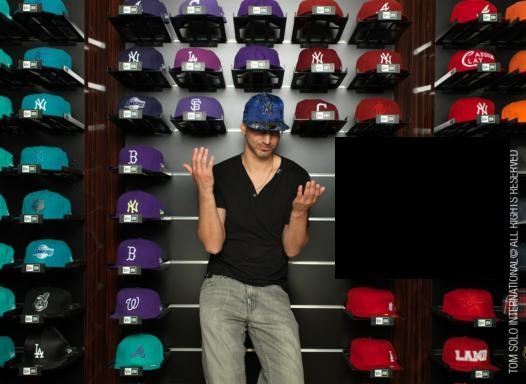


Categoría: 'legos'
  Ground Truth (Cantidad): 512
  Archivo de Imagen: 6860.jpg


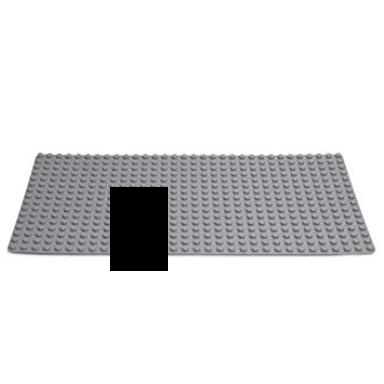


Categoría: 'skateboard'
  Ground Truth (Cantidad): 26
  Archivo de Imagen: 6919.jpg


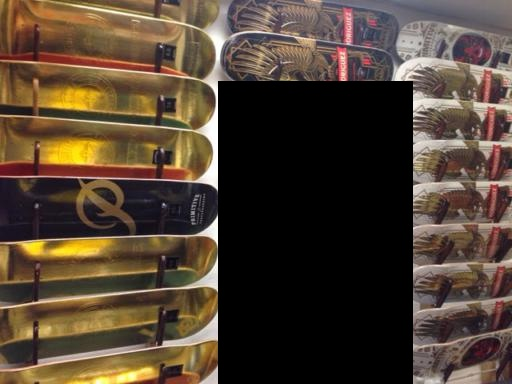


Categoría: 'stamps'
  Ground Truth (Cantidad): 28
  Archivo de Imagen: 6923.jpg


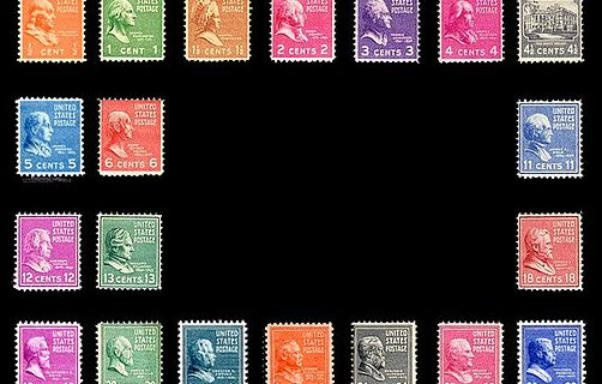


Categoría: 'flower pots'
  Ground Truth (Cantidad): 25
  Archivo de Imagen: 6955.jpg


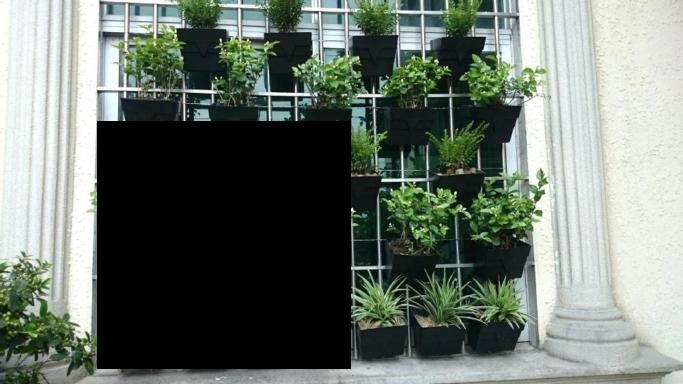


Categoría: 'alcohol bottles'
  Ground Truth (Cantidad): 116
  Archivo de Imagen: 6967.jpg


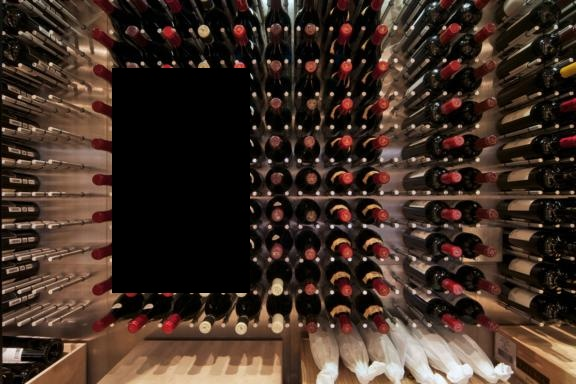


Categoría: 'cartridges'
  Ground Truth (Cantidad): 41
  Archivo de Imagen: 6995.jpg


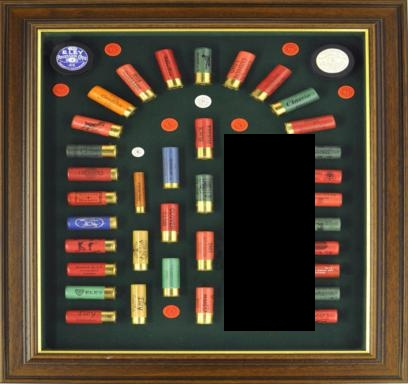


Categoría: 'chopstick'
  Ground Truth (Cantidad): 24
  Archivo de Imagen: 7001.jpg


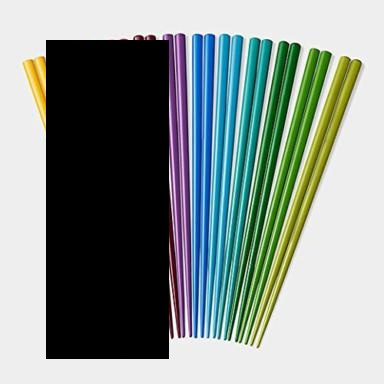


Categoría: 'straws'
  Ground Truth (Cantidad): 113
  Archivo de Imagen: 7127.jpg


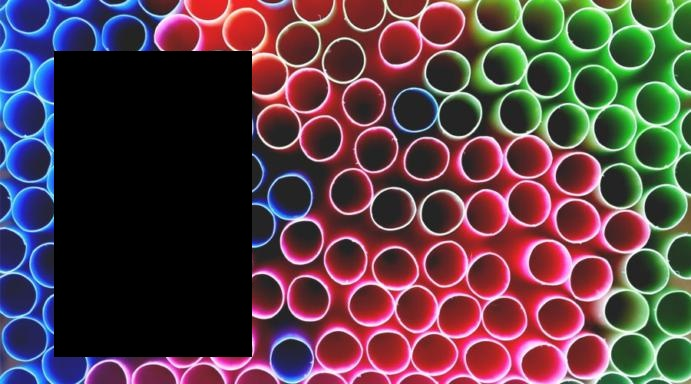


Categoría: 'milk cartons'
  Ground Truth (Cantidad): 34
  Archivo de Imagen: 7169.jpg


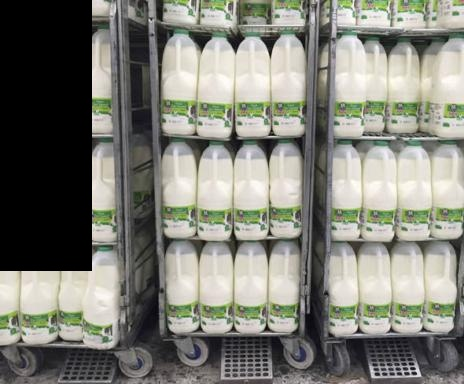


Categoría: 'boats'
  Ground Truth (Cantidad): 98
  Archivo de Imagen: 7180.jpg


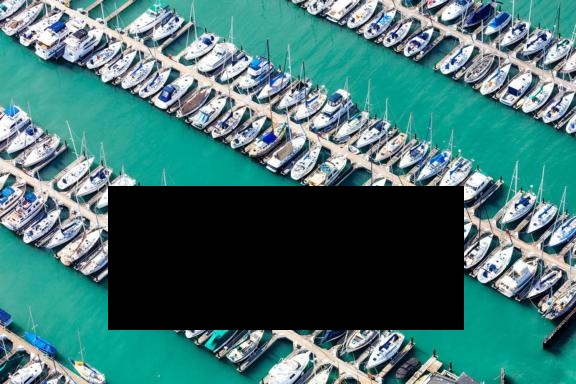


Categoría: 'people'
  Ground Truth (Cantidad): 36
  Archivo de Imagen: 7311.jpg


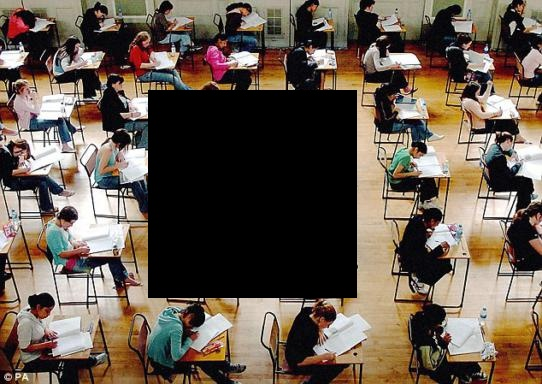


Categoría: 'pens'
  Ground Truth (Cantidad): 31
  Archivo de Imagen: 7626.jpg


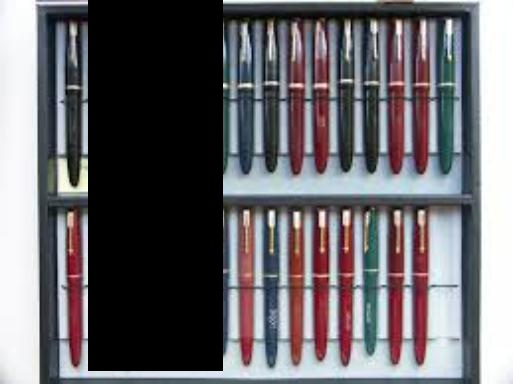


Categoría: 'watches'
  Ground Truth (Cantidad): 30
  Archivo de Imagen: 7633.jpg


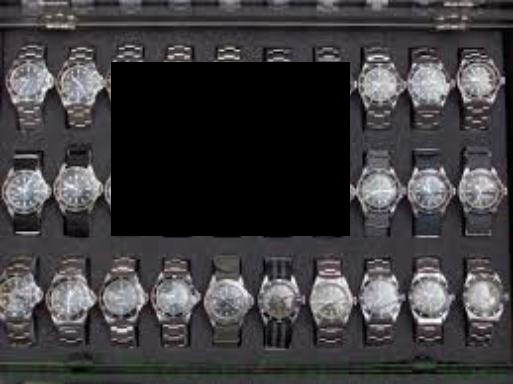


Categoría: 'books'
  Ground Truth (Cantidad): 15
  Archivo de Imagen: 862.jpg


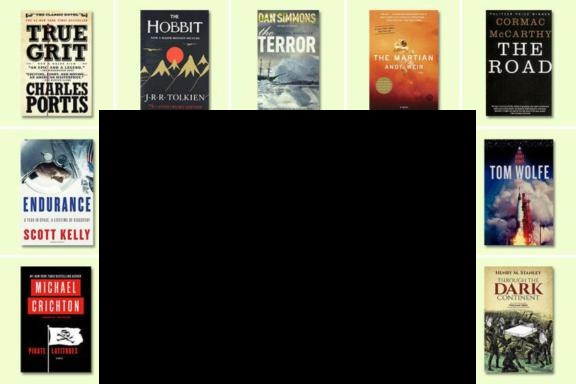


Categoría: 'plates'
  Ground Truth (Cantidad): 59
  Archivo de Imagen: 886.jpg


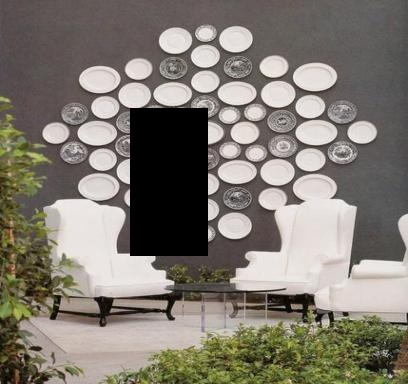

In [ ]:
from IPython.display import Image, display

# Rutas base para las imágenes
REAL_IMAGE_DIR = '/content/real_dataset/'

# Obtener categorías únicas de 'object'
unique_objects = real_metadata_df['object'].unique()

print("Ejemplos de categorías en real_metadata_df:")
for obj in unique_objects:
    # Encontrar la primera fila para esta categoría
    first_entry = real_metadata_df[real_metadata_df['object'] == obj].iloc[0]

    image_file = first_entry['image_file']
    ground_truth = first_entry['ground_truth']

    print(f"\nCategoría: '{obj}'")
    print(f"  Ground Truth (Cantidad): {ground_truth}")
    print(f"  Archivo de Imagen: {image_file}")

    # Mostrar la imagen
    image_path = os.path.join(REAL_IMAGE_DIR, image_file)
    if os.path.exists(image_path):
        display(Image(filename=image_path, width=200)) # Ajustar el ancho según sea necesario
    else:
        print(f"  Advertencia: La imagen {image_file} no se encontró en {REAL_IMAGE_DIR}")

### Formato de Cada Categoría en `synthetic_metadata_df`

A continuación, se muestra la primera pregunta encontrada para cada categoría única de 'shape' en el dataset sintético, junto con su `ground_truth` y la imagen correspondiente.

Ejemplos de categorías (shape) en synthetic_metadata_df:

Categoría (Shape): 'circle'
  Ground Truth (Cantidad): 5
  Color: blue
  Dot Shape: circle
  Archivo de Imagen: circle_5_dots_0_blue_dots.png


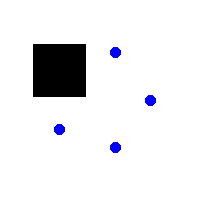


Categoría (Shape): 'rectangle'
  Ground Truth (Cantidad): 5
  Color: blue
  Dot Shape: circle
  Archivo de Imagen: rectangle_5_dots_0_blue_dots.png


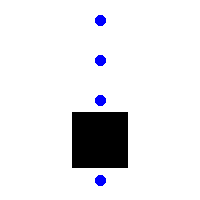


Categoría (Shape): 'triangle'
  Ground Truth (Cantidad): 6
  Color: blue
  Dot Shape: circle
  Archivo de Imagen: triangle_6_dots_0_blue_dots.png


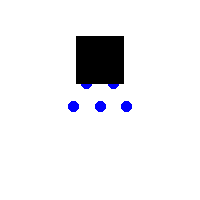

In [ ]:
from IPython.display import Image, display

# Rutas base para las imágenes
SYNTHETIC_IMAGE_DIR = '/content/synthetic_dataset/'

# Obtener categorías únicas de 'shape'
unique_shapes = synthetic_metadata_df['shape'].unique()

print("Ejemplos de categorías (shape) en synthetic_metadata_df:")
for shape in unique_shapes:
    # Encontrar la primera fila para esta categoría
    first_entry = synthetic_metadata_df[synthetic_metadata_df['shape'] == shape].iloc[0]

    image_file = first_entry['image_file']
    ground_truth = first_entry['ground_truth']
    color = first_entry['color']
    dot_shape = first_entry['dot_shape']

    print(f"\nCategoría (Shape): '{shape}'")
    print(f"  Ground Truth (Cantidad): {ground_truth}")
    print(f"  Color: {color}")
    print(f"  Dot Shape: {dot_shape}")
    print(f"  Archivo de Imagen: {image_file}")

    # Mostrar la imagen
    image_path = os.path.join(SYNTHETIC_IMAGE_DIR, image_file)
    if os.path.exists(image_path):
        display(Image(filename=image_path, width=200)) # Ajustar el ancho según sea necesario
    else:
        print(f"  Advertencia: La imagen {image_file} no se encontró en {SYNTHETIC_IMAGE_DIR}")

### Descripción del Benchmark CAPTURe

El benchmark CAPTURe (Counting objects Accurately in Perceptual Tasks with Unbiased REpresentations) es un conjunto de datos diseñado para evaluar la capacidad de los modelos de visión por computadora para contar objetos de manera precisa, especialmente en escenarios donde la variabilidad perceptual puede introducir sesgos. Este benchmark se enfoca en la robustez de los modelos frente a diversas características visuales.

**Información que manejamos del benchmark:**

1.  **Datasets Componentes:** CAPTURe se compone de dos tipos principales de datasets:
    *   **Dataset Real (`real_metadata_df`):** Contiene imágenes del mundo real con una variedad de objetos cotidianos (como llaves de teclado, tapas de botellas, gafas de sol, etc.). Hemos revisado 824 entradas de este dataset, donde cada entrada incluye la ruta del archivo de imagen, una estimación de probabilidad (`log_prob`), la suma de mapas de densidad (`density_map_sum`), la cantidad real de objetos (`ground_truth`), el tipo de objeto (`object`) y las coordenadas de sus cuadros delimitadores (`bbox`). Las imágenes muestran una alta variabilidad en el tamaño, la pose y la apariencia de los objetos.
    *   **Dataset Sintético (`synthetic_metadata_df`):** Consiste en imágenes generadas artificialmente con objetos geométricos simples (círculos, rectángulos, triángulos) y puntos de diferentes colores y formas. Hemos analizado 1150 entradas de este dataset, que incluyen la ruta del archivo de imagen, la cantidad real de objetos (`ground_truth`), la forma del objeto principal (`shape`), el color, la forma de los puntos (`dot_shape`) y sus posiciones. Este dataset permite un control preciso sobre las características visuales para estudiar cómo afectan al conteo.

2.  **Objetivo Principal:** El objetivo de CAPTURe es ir más allá de la simple identificación de objetos para abordar el problema del **conteo de objetos**, que es fundamental en muchas aplicaciones. Al combinar datasets reales y sintéticos, el benchmark busca desafiar a los modelos a generalizar el conteo a través de diferentes dominios visuales y condiciones.

3.  **Manejo de la Información:**
    *   Hemos cargado y estructurado los metadatos de ambos datasets en DataFrames de pandas para facilitar su exploración.
    *   Hemos analizado la cantidad de preguntas/entradas en cada dataset, observando que el dataset sintético tiene un mayor número de ejemplos.
    *   Hemos explorado las características de cada categoría, mostrando ejemplos visuales para entender la diversidad de los objetos y las variaciones dentro de las categorías (e.g., diferentes formas en el dataset sintético).
    *   Las columnas como `ground_truth`, `object`, `shape`, `color`, y `dot_shape` son cruciales para entender las preguntas y las respuestas esperadas en el benchmark.

En resumen, CAPTURe es una herramienta valiosa para investigar y desarrollar modelos de conteo de objetos que sean robustos y capaces de manejar la complejidad visual del mundo real y la precisión controlada del mundo sintético.

### Distribución de la Cantidad de Elementos (Ground Truth)

Para entender cuántos elementos se piden contar típicamente en cada dataset, podemos visualizar la distribución de la columna `ground_truth`. Esto nos mostrará si las preguntas se concentran en cantidades pequeñas, grandes, o si están distribuidas uniformemente.

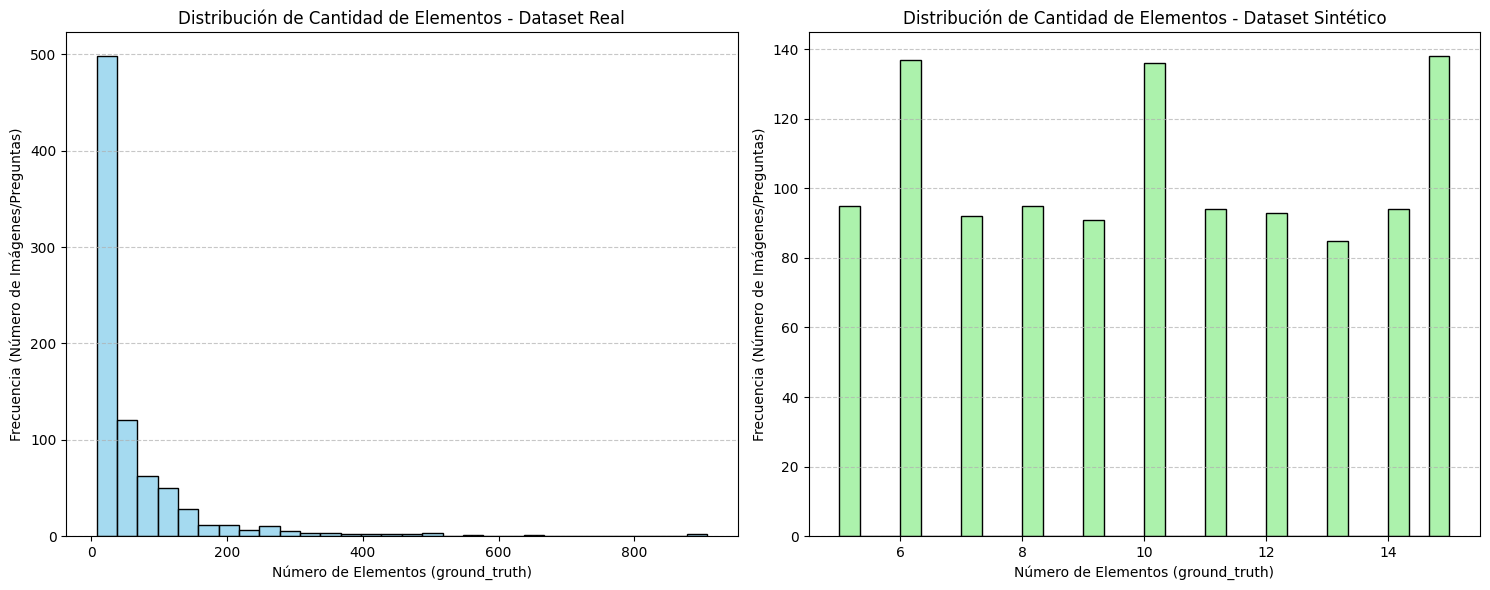

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Intentar cargar los datos si el entorno de ejecución se ha reiniciado
if 'real_metadata_df' not in globals() or 'synthetic_metadata_df' not in globals():
    print("Cargando metadatos nuevamente...")
    from huggingface_hub import hf_hub_download
    real_meta = hf_hub_download(repo_id="atinp/CAPTURe", filename="real_metadata.json", repo_type="dataset")
    syn_meta  = hf_hub_download(repo_id="atinp/CAPTURe", filename="synthetic_metadata.json", repo_type="dataset")
    real_metadata_df = pd.read_json(real_meta)
    synthetic_metadata_df = pd.read_json(syn_meta)

# Crear una figura con dos subgráficos
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Gráfico para el Dataset Real
sns.histplot(data=real_metadata_df, x='ground_truth', bins=30, ax=axes[0], color='skyblue')
axes[0].set_title('Distribución de Cantidad de Elementos - Dataset Real')
axes[0].set_xlabel('Número de Elementos (ground_truth)')
axes[0].set_ylabel('Frecuencia (Número de Imágenes/Preguntas)')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Gráfico para el Dataset Sintético
sns.histplot(data=synthetic_metadata_df, x='ground_truth', bins=30, ax=axes[1], color='lightgreen')
axes[1].set_title('Distribución de Cantidad de Elementos - Dataset Sintético')
axes[1].set_xlabel('Número de Elementos (ground_truth)')
axes[1].set_ylabel('Frecuencia (Número de Imágenes/Preguntas)')
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

# Ajustar el diseño y mostrar
plt.tight_layout()
plt.show()


### Tablas de Frecuencia por Número de Elementos

A continuación, se muestran las tablas exactas con el "Número de elementos" (`ground_truth`) y la "Cantidad" de imágenes asociadas a cada número para ambos datasets.

In [ ]:
from IPython.display import display

# Crear tabla para el dataset real
tabla_real = real_metadata_df['ground_truth'].value_counts().reset_index()
tabla_real.columns = ['Número de Elementos', 'Cantidad']
# Ordenar por el número de elementos de menor a mayor
tabla_real = tabla_real.sort_values(by='Número de Elementos').reset_index(drop=True)

print("--- Tabla Dataset Real ---")
display(tabla_real)

# Crear tabla para el dataset sintético
tabla_sintetica = synthetic_metadata_df['ground_truth'].value_counts().reset_index()
tabla_sintetica.columns = ['Número de Elementos', 'Cantidad']
# Ordenar por el número de elementos de menor a mayor
tabla_sintetica = tabla_sintetica.sort_values(by='Número de Elementos').reset_index(drop=True)

print("\n--- Tabla Dataset Sintético ---")
display(tabla_sintetica)


--- Tabla Dataset Real ---


,Número de Elementos,Cantidad
0,8,13
1,9,25
2,10,8
3,11,6
4,12,121
...,...,...
180,512,1
181,577,1
182,645,1
183,885,1



--- Tabla Dataset Sintético ---


,Número de Elementos,Cantidad
0,5,95
1,6,137
2,7,92
3,8,95
4,9,91
5,10,136
6,11,94
7,12,93
8,13,85
9,14,94
